# Recommendation 05 — Diagnostica query LLM vs GTE diretto (fase 2A)

**Obiettivo:** interpretare il pilota di `recommendation_04` **senza nuove chiamate LLM, senza modificare agenti/MCP e senza ricalcolare gli embedding dei film**.

1. Controllo integrità: cache LLM, hash di input/prompt, ranking congelati e stesse osservazioni.
2. Diagnostica *file-only*: overlap top 10, raccomandazioni perse/guadagnate, etichette A/B, esempi reali, descrizioni delle query.
3. Diagnostica vettoriale **opzionale**: ricodifica **solo le query testuali già salvate**, recupera gli embedding film invariati da Qdrant, confronta query/centroidi e controfattuali del feedback negativo.

**Non è tuning:** nessuna nuova ricerca di prompt/α, nessuna inferenza Gemini. La diagnosi dovrebbe essere usata sulla **validation**; non scegliere nuove impostazioni guardando il test. I ranking con film senza rating non sono automaticamente errori di raccomandazione.

**Privacy sperimentale:** i target nascosti vengono letti **solo dopo** aver letto e verificato i ranking congelati; i report con rating nascosti sono salvati sotto `private_evaluation/`. L'analisi è post-hoc: non modifica le predizioni.

## 0 — Configurazione (modifica qui solo se necessario)

In [1]:
from pathlib import Path
import os, json, hashlib, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT_OVERRIDE = None         # es. Path('/percorso/al/progetto')
PROTOCOL_ID = 'rs_coldstart_v1'
RUN_MODE = 'pilot_validation'       # 'pilot_validation', 'full_validation'; 'test' SOLO diagnosi descrittiva post-hoc
RUN_VECTOR_DIAGNOSTICS = True      # False = analisi completa dei file senza Qdrant/encoder
SHOW_CASES = 7
TOP_K = 10
POS_MIN, NEG_MAX = 4.0, 2.0

QDRANT_URL = 'http://localhost:6333'
QDRANT_API_KEY = None
QDRANT_COLLECTION_OVERRIDE = None  # None = usa il run_manifest del notebook 04
QDRANT_MOVIE_ID_KEY = 'resource_id'
QDRANT_VECTOR_NAME = None
GTE_QUERY_BATCH_SIZE = 16


def locate_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        return Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    here = Path.cwd().resolve()
    for root in (here, *here.parents):
        if (root/'datasets/processed/recommendation_protocol'/PROTOCOL_ID/'protocol_manifest.json').is_file():
            return root
    raise FileNotFoundError('Protocollo 10/20 non trovato. Configura PROJECT_ROOT_OVERRIDE.')

ROOT=locate_root()
BASE=ROOT/'datasets/processed/recommendation_protocol'/PROTOCOL_ID
INPUT=BASE/'inputs'
PHASE2A=BASE/'evaluations'/'llm_gte_phase2a'
RUN=PHASE2A/RUN_MODE
BASELINE=BASE/'evaluations'/'baseline_mf_gte'
PRIVATE=BASE/'private_evaluation'
OUT=PRIVATE/'diagnostics_llm_query'/RUN_MODE
MOVIES_PATH=ROOT/'datasets/raw/ml-latest-small/movies.csv'
if RUN_MODE not in ('pilot_validation','full_validation','test'):
    raise ValueError('RUN_MODE non valido')
print('ROOT:',ROOT, '| SOURCE:', RUN, '| VECTOR_DIAGNOSTICS:',RUN_VECTOR_DIAGNOSTICS)

ROOT: /Users/danieleraveglia/Documents/uniMi/TESI/progetto | SOURCE: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_v1/evaluations/llm_gte_phase2a/pilot_validation | VECTOR_DIAGNOSTICS: True


## 1 — Congela le fonti: file prodotti dal notebook 04, baseline 02 e cache profili

Per evitare di associare una query vecchia al ranking attuale, ogni profilo viene recuperato dalla cache con **scenario, livello, SHA256 degli input visibili, SHA256 del prompt e modello**.

In [2]:
manifest=json.loads((BASE/'protocol_manifest.json').read_text(encoding='utf-8'))
run_manifest=json.loads((RUN/'run_manifest.json').read_text(encoding='utf-8'))
config=json.loads((BASELINE/'model_config.json').read_text(encoding='utf-8'))
for obj in (manifest,run_manifest,config):
    assert obj.get('protocol_id')==PROTOCOL_ID, 'Protocol ID differente'
assert run_manifest.get('validation_or_test') == ('test' if RUN_MODE=='test' else 'validation')

movies=pd.read_csv(MOVIES_PATH)[['movieId','title','genres']]
catalog=pd.read_csv(INPUT/'catalog_movie_ids.csv')
visible=pd.read_csv(INPUT/'visible_interactions.csv')
scenarios=pd.read_csv(INPUT/'scenarios.csv')
levels=pd.read_csv(INPUT/'scenario_levels.csv')
llm_rank=pd.read_csv(RUN/'rankings_llm_gte.csv')
llm_metrics=pd.read_csv(RUN/'metrics_per_scenario_A_B.csv')
base_path=ROOT/run_manifest['baseline_file']
if not base_path.is_file(): raise FileNotFoundError(f'Ranking baseline mancante: {base_path}')
base_rank=pd.read_csv(base_path)

for x in (movies,catalog,visible,llm_rank,base_rank):
    x['movieId']=x['movieId'].astype('int64')
for x in (visible,levels,llm_rank,base_rank,llm_metrics): x['k']=x['k'].astype(int)
for x in (llm_rank,base_rank): x['rank']=x['rank'].astype(int)
for x in (visible,levels,llm_rank,base_rank,llm_metrics,scenarios):
    x['scenario_id']=x['scenario_id'].astype(str)
assert movies.movieId.is_unique and catalog.movieId.is_unique
catalog_ids=np.sort(catalog.movieId.to_numpy('int64'))
catalog_set=set(map(int,catalog_ids))
idx={int(mid):j for j,mid in enumerate(catalog_ids)}
info=movies.set_index('movieId')

required_rank={'scenario_id','k','model','movieId','rank','score'}
for name,df in [('LLM',llm_rank),('baseline',base_rank)]:
    assert required_rank.issubset(df),f'{name}: colonne mancanti {required_rank-set(df)}'
assert set(llm_rank.model)=={'llm_gte_semantic'}
keys=set(map(tuple,llm_rank[['scenario_id','k']].drop_duplicates().itertuples(index=False,name=None)))
expected_keys=set(map(tuple,levels.loc[levels.scenario_id.isin({s for s,k in keys}) &
                                        levels.k.isin({k for s,k in keys}),['scenario_id','k']]
                             .itertuples(index=False,name=None)))
assert keys==expected_keys, 'Livelli incompleti rispetto ai valori di k disponibili nel run'
assert llm_rank.groupby(['scenario_id','k']).size().eq(TOP_K).all()
assert llm_rank[['scenario_id','k','rank']].duplicated().sum()==0
assert llm_rank[['scenario_id','k','movieId']].duplicated().sum()==0
assert set(llm_rank.movieId).issubset(catalog_set)

alpha=float(config['gte_neg_alpha_selected'])
base_gte_name=('gte_direct' if RUN_MODE=='test' else f'gte_negalpha_{alpha:g}')
sel_base=base_rank.loc[base_rank.model==base_gte_name].copy()
sel_base=sel_base.loc[sel_base[['scenario_id','k']].apply(tuple,axis=1).isin(keys)]
if sel_base.empty: raise ValueError(f'Baseline GTE {base_gte_name} non trovata')
sel_base['model']='gte_direct'
assert set(map(tuple,sel_base[['scenario_id','k']].drop_duplicates().itertuples(index=False,name=None)))==keys
assert sel_base.groupby(['scenario_id','k']).size().eq(TOP_K).all()
assert set(sel_base.movieId).issubset(catalog_set)

all_ranks=pd.concat([sel_base,llm_rank],ignore_index=True)
observed={(str(sid),int(k)):g[['movieId','rating']].copy() for (sid,k),g in visible.groupby(['scenario_id','k'])}
for (sid,k,model),g in all_ranks.groupby(['scenario_id','k','model']):
    assert set(g.movieId).isdisjoint(set(observed.get((sid,k),pd.DataFrame(columns=['movieId'])).movieId)),(sid,k,model)
    assert sorted(g['rank'].tolist())==list(range(1,TOP_K+1))

lookup=movies.set_index('movieId')[['title','genres']].to_dict('index')
def observed_payload(obs):
    return [{'movie_id':int(r.movieId),'title':str(lookup[int(r.movieId)]['title']),
             'genres':str(lookup[int(r.movieId)]['genres']).replace('|',', '),
             'rating':float(r.rating)} for r in obs.sort_values('movieId').itertuples(index=False)]
def obs_hash(obs):
    return hashlib.sha256(json.dumps(observed_payload(obs),sort_keys=True,ensure_ascii=False).encode('utf-8')).hexdigest()

CACHE=PHASE2A/'semantic_profiles_cache.jsonl'
if not CACHE.exists():raise FileNotFoundError(f'Cache profili necessaria: {CACHE}')
expected_prompt=run_manifest['prompt_sha256']
expected_model=run_manifest['provider_profile']
cache={}
for line in CACHE.read_text(encoding='utf-8').splitlines():
    if not line.strip():continue
    p=json.loads(line)
    key=(str(p['scenario_id']),int(p['k']),str(p['input_hash']),str(p['prompt_hash']),str(p['profile_model']))
    cache[key]=p  # ultimo record con identità completa
rows=[]
for sid,k in sorted(keys):
    obs=observed.get((sid,k),pd.DataFrame(columns=['movieId','rating']))
    assert len(obs)==k,(sid,k,len(obs))
    key=(sid,k,obs_hash(obs),expected_prompt,expected_model)
    if key not in cache:raise ValueError(f'Profilo mancante o hash errato: {sid}, k={k}; verifica cache e run_manifest')
    p=dict(cache[key]);p.pop('trace',None);rows.append(p)
profiles=pd.DataFrame(rows)
assert len(profiles)==len(keys)
for p in profiles.to_dict('records'):
    ob=observed.get((p['scenario_id'],int(p['k'])),pd.DataFrame(columns=['rating']))
    for field,expect in [('positive_query',(ob.rating>=POS_MIN).any()),('negative_query',(ob.rating<=NEG_MAX).any())]:
        val=p.get(field)
        present=isinstance(val,str) and bool(val.strip())
        assert present==bool(expect),(p['scenario_id'],p['k'],field)
print('Profili verificati:',len(profiles),'| baseline model:',base_gte_name,'| film catalogo:',len(catalog_ids))
print('Query positive:',profiles.positive_query.notna().sum(),'negative:',profiles.negative_query.notna().sum())
display(profiles[['scenario_id','k','positive_query','negative_query']].head(8))

Profili verificati: 50 | baseline model: gte_negalpha_0.2 | film catalogo: 1996
Query positive: 37 negative: 13


,scenario_id,k,positive_query,negative_query
0,validation_u100_r0,0,NaN,NaN
1,validation_u100_r0,1,"Drama and romance themes, period pieces, and e...",NaN
2,validation_u100_r0,3,"drama, romance, comedy, period drama, emotiona...",NaN
3,validation_u100_r0,5,"drama, romance, emotional storytelling, coming...",NaN
4,validation_u100_r0,10,"Drama, romance, comedies and musicals, featuri...",Horror and thriller films involving intense su...
5,validation_u106_r0,0,NaN,NaN
6,validation_u106_r0,1,NaN,NaN
7,validation_u106_r0,3,epic adventure and fantasy films featuring mag...,NaN


## 2 — Diagnostica senza vettori e senza giudizi privati

Testiamo se le query diventano più generiche al crescere di k (lunghezza, numero di generi citati, numero di categorie positive/negative). **Queste sono proxy lessicali**, non misure affidabili della qualità del testo.

In [3]:
genre_vocab=sorted({term.strip() for s in movies.genres.astype(str) for term in s.split('|') if term.strip() and term!='(no genres listed)'},key=len,reverse=True)
def genre_mentions(text):
    if not isinstance(text,str) or not text.strip():return []
    q=text.lower()
    return sorted({g for g in genre_vocab if re.search(r'(?<!\w)'+re.escape(g.lower())+r'(?!\w)',q)})
def word_count(text):
    return len(re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?",text)) if isinstance(text,str) else 0

query_diag=[]
for p in profiles.to_dict('records'):
    sid,k=str(p['scenario_id']),int(p['k'])
    obs=observed[(sid,k)] if (sid,k) in observed else pd.DataFrame(columns=['movieId','rating'])
    pos=obs[obs.rating>=POS_MIN];neg=obs[obs.rating<=NEG_MAX]
    qpos=p.get('positive_query');qneg=p.get('negative_query')
    query_diag.append({'scenario_id':sid,'k':k,'n_positive_visible':len(pos),'n_negative_visible':len(neg),
                       'n_neutral_visible':k-len(pos)-len(neg),
                       'positive_word_count':word_count(qpos),'negative_word_count':word_count(qneg),
                       'positive_genres_literal':genre_mentions(qpos),'negative_genres_literal':genre_mentions(qneg),
                       'n_genres_positive_literal':len(genre_mentions(qpos)),
                       'n_genres_negative_literal':len(genre_mentions(qneg)),
                       'pos_query_per_positive_film':word_count(qpos)/max(len(pos),1) if len(pos) else np.nan})
query_diag=pd.DataFrame(query_diag)
display(query_diag.groupby('k')[['n_positive_visible','n_negative_visible','positive_word_count',
                                 'n_genres_positive_literal','negative_word_count']].mean().round(2))
print('Attenzione: un genere può essere espresso con sinonimi; non leggere questi conteggi come classificazione semantica.')

,n_positive_visible,n_negative_visible,positive_word_count,n_genres_positive_literal,negative_word_count
k,,,,,
0,0.0,0.0,0.0,0.0,0.0
1,0.7,0.1,7.6,1.2,0.7
3,2.1,0.1,14.1,3.2,0.3
5,3.1,0.4,13.1,3.6,2.4
10,6.2,0.8,20.2,5.1,5.0


Attenzione: un genere può essere espresso con sinonimi; non leggere questi conteggi come classificazione semantica.


## 3 — Unisci i ranking già prodotti, senza ricalcolarli

Misuriamo sovrapposizione e discontinuità del ranking. Gli score **non** sono confrontabili in valore assoluto fra GTE diretto e LLM: le rappresentazioni sono diverse.

In [4]:
def ranked_list(frame,sid,k,model):
    g=frame.loc[(frame.scenario_id==sid)&(frame.k==k)&(frame.model==model)].sort_values('rank')
    out=g.movieId.astype(int).tolist()
    assert len(out)==TOP_K
    return out

rank_diagnostics=[]
for sid,k in sorted(keys):
    direct=ranked_list(all_ranks,sid,k,'gte_direct')
    sem=ranked_list(all_ranks,sid,k,'llm_gte_semantic')
    common=len(set(direct)&set(sem))
    rank_diagnostics.append({'scenario_id':sid,'k':k,'overlap@10':common,
                             'jaccard@10':common/(2*TOP_K-common),
                             'n_replaced':TOP_K-common,
                             'removed_by_llm':sorted(set(direct)-set(sem)),
                             'added_by_llm':sorted(set(sem)-set(direct))})
rank_diagnostics=pd.DataFrame(rank_diagnostics)
summary_no_gt=rank_diagnostics.groupby('k')[['overlap@10','jaccard@10','n_replaced']].agg(['mean','median']).round(2)
display(summary_no_gt)

overlap@10        jaccard@10        n_replaced       
         mean median       mean median       mean median
k                                                       
0        10.0   10.0       1.00   1.00        0.0    0.0
1         4.0    2.5       0.34   0.14        6.0    7.5
3         1.3    0.5       0.08   0.03        8.7    9.5
5         1.6    0.5       0.10   0.03        8.4    9.5
10        1.4    0.0       0.10   0.00        8.6   10.0

## 4 — Apri il ground truth **solo dopo** aver congelato i ranking

Le etichette A e B sono utilizzate **per capire gli errori**, non per modificare la classifica. Per B rientrano anche i rating P non rivelati; i film non giudicati restano `unjudged`, non negativi.

In [5]:
private_profile=pd.read_csv(PRIVATE/'private_profile.csv')
private_fixed=pd.read_csv(PRIVATE/'private_fixed_gt.csv')
private_extra=pd.read_csv(PRIVATE/'private_additional.csv')
for df in (private_profile,private_fixed,private_extra):
    df['scenario_id']=df['scenario_id'].astype(str);df['movieId']=df['movieId'].astype('int64')
assert private_profile.groupby('scenario_id').size().eq(10).all()
assert private_fixed.groupby('scenario_id').size().eq(20).all()
truth_maps={}
for sid,k in sorted(keys):
    p=private_profile.loc[(private_profile.scenario_id==sid)&(private_profile.reveal_order>k)]
    a=private_fixed.loc[private_fixed.scenario_id==sid]
    e=private_extra.loc[private_extra.scenario_id==sid]
    assert len(a)==20
    ga=dict(zip(a.movieId.astype(int),a.rating.astype(float)))
    gb=dict(ga)
    for g in (e,p):
        add=dict(zip(g.movieId.astype(int),g.rating.astype(float)))
        assert not set(gb).intersection(add),f'Target overlap: {sid}'
        gb.update(add)
    truth_maps[(sid,k)]={'A':ga,'B':gb}

annotated=[]
for r in all_ranks.itertuples(index=False):
    mid=int(r.movieId);sid=str(r.scenario_id);k=int(r.k)
    ta=truth_maps[(sid,k)]['A'];tb=truth_maps[(sid,k)]['B']
    annotated.append({'scenario_id':sid,'k':k,'model':r.model,'movieId':mid,'rank':int(r.rank),
                      'score':float(r.score),'title':lookup[mid]['title'],'genres':lookup[mid]['genres'],
                      'rating_A':ta.get(mid,np.nan),'rating_B':tb.get(mid,np.nan),
                      'label_A':('positive' if ta[mid]>=POS_MIN else 'negative' if ta[mid]<=NEG_MAX else 'neutral') if mid in ta else 'unjudged',
                      'label_B':('positive' if tb[mid]>=POS_MIN else 'negative' if tb[mid]<=NEG_MAX else 'neutral') if mid in tb else 'unjudged'})
annotated=pd.DataFrame(annotated)

metric_lookup=llm_metrics.loc[llm_metrics.model.isin(['gte_direct','llm_gte_semantic'])].copy()
metric_lookup=metric_lookup[['scenario_id','k','model','scheme','ndcg@10','recall@10','hr@10','n_unjudged_topk']]
assert not metric_lookup[['scenario_id','k','model','scheme']].duplicated().any()
per_case=[]
for row in rank_diagnostics.itertuples(index=False):
    sid=row.scenario_id;k=int(row.k)
    direct=set(ranked_list(all_ranks,sid,k,'gte_direct'))
    sem=set(ranked_list(all_ranks,sid,k,'llm_gte_semantic'))
    for scheme in ['A','B']:
        gt=truth_maps[(sid,k)][scheme]
        positives={mid for mid,r in gt.items() if r>=POS_MIN}
        m=metric_lookup.loc[(metric_lookup.scenario_id==sid)&(metric_lookup.k==k)&(metric_lookup.scheme==scheme)]
        m=m.set_index('model')
        assert {'gte_direct','llm_gte_semantic'}.issubset(set(m.index))
        nposnew=len((sem-direct)&positives)
        nposlost=len((direct-sem)&positives)
        per_case.append({'scenario_id':sid,'k':k,'scheme':scheme,'overlap@10':int(row._asdict().get('_2',len(direct&sem))),
                         'new_positive_hits':nposnew,'lost_positive_hits':nposlost,
                         'new_unjudged':sum(mid not in gt for mid in sem-direct),
                         'lost_unjudged':sum(mid not in gt for mid in direct-sem),
                         'delta_ndcg10':float(m.loc['llm_gte_semantic','ndcg@10']-m.loc['gte_direct','ndcg@10']),
                         'llm_ndcg10':float(m.loc['llm_gte_semantic','ndcg@10']),
                         'gte_ndcg10':float(m.loc['gte_direct','ndcg@10'])})
per_case=pd.DataFrame(per_case)
# Le metriche esportate dal 04 e il numero di hit ricalcolato qui devono essere coerenti.
for (sid,k,model),g in annotated.groupby(['scenario_id','k','model']):
    for scheme in ['A','B']:
        row=llm_metrics.loc[(llm_metrics.scenario_id==sid)&(llm_metrics.k==k)&
                            (llm_metrics.model==model)&(llm_metrics.scheme==scheme)]
        assert len(row)==1
        expected=int((g['label_'+scheme]=='positive').sum())
        assert int(row.iloc[0]['n_hits_topk'])==expected,(sid,k,model,scheme)

display(per_case.groupby(['scheme','k'])[['overlap@10','new_positive_hits','lost_positive_hits',
                                         'new_unjudged','delta_ndcg10']].mean().round(4))

overlap@10  new_positive_hits  lost_positive_hits  new_unjudged  \
scheme k                                                                     
A      0         10.0                0.0                 0.0           0.0   
       1          4.0                0.0                 0.1           5.9   
       3          1.3                0.0                 0.4           8.7   
       5          1.6                0.1                 0.3           8.1   
       10         1.4                0.2                 0.6           8.4   
B      0         10.0                0.0                 0.0           0.0   
       1          4.0                0.5                 1.0           5.1   
       3          1.3                0.3                 1.8           7.9   
       5          1.6                0.3                 1.6           7.7   
       10         1.4                0.4                 1.5           8.2   

           delta_ndcg10  
scheme k                 
A      0         0.0000  
       1        -0.0066  
       3        -0.0295  
       5        -0.0036  
       10       -0.0241  
B      0         0.0000  
       1        -0.0653  
       3        -0.1509  
       5        -0.1290  
       10       -0.0968

## 5 — Esempi qualitativi: film rivelati, query LLM e top-10 dei due metodi

Gli scenari sono scelti **solo** dal pilota di validation, privilegiando casi con diminuzione/aumento di NDCG B e feedback negativo. La selezione è diagnostica, non rappresentativa della popolazione.

In [6]:
scenarios_owner=scenarios.set_index('scenario_id')['userId'].to_dict()
results_b=per_case.loc[(per_case.scheme=='B')&(per_case.k>0)]
case_keys=[]
for df in [results_b.nsmallest(2,'delta_ndcg10'),results_b.nlargest(2,'delta_ndcg10')]:
    case_keys.extend(map(tuple,df[['scenario_id','k']].itertuples(index=False,name=None)))
neg_keys=query_diag.loc[(query_diag.n_negative_visible>0)&(query_diag.k>0),['scenario_id','k']]
case_keys.extend(map(tuple,neg_keys.itertuples(index=False,name=None)))
case_keys.extend(map(tuple,results_b.loc[results_b.k==10,['scenario_id','k']].itertuples(index=False,name=None)))
case_keys=list(dict.fromkeys(case_keys))[:SHOW_CASES]

def show_example(sid,k):
    q=profiles.loc[(profiles.scenario_id==sid)&(profiles.k==k)].iloc[0]
    print('\n'+'='*80)
    print(f'UTENTE {scenarios_owner[sid]} | scenario={sid} | k={k}')
    obs=observed[(sid,k)] if (sid,k) in observed else pd.DataFrame(columns=['movieId','rating'])
    if not obs.empty:
        visible_view=obs.merge(movies,on='movieId',how='left',validate='many_to_one')
        display(visible_view[['title','genres','rating']].sort_values('rating',ascending=False))
    else:print('Nessuna interazione visibile')
    print('Query POS:', q['positive_query'] if isinstance(q['positive_query'],str) else '(assente)')
    print('Query NEG:', q['negative_query'] if isinstance(q['negative_query'],str) else '(assente)')
    print('Rationale:',q.get('brief_rationale',''))
    for model in ['gte_direct','llm_gte_semantic']:
        print('---',model,'---')
        g=annotated.loc[(annotated.scenario_id==sid)&(annotated.k==k)&(annotated.model==model)]
        # NON confrontare numericamente gli score fra i due metodi
        display(g[['rank','title','genres','score','rating_B','label_A','label_B']].sort_values('rank'))
    m=per_case.loc[(per_case.scenario_id==sid)&(per_case.k==k),['scheme','delta_ndcg10','new_positive_hits','lost_positive_hits']]
    display(m)

for sid,k in case_keys:show_example(sid,int(k))


UTENTE 199 | scenario=validation_u199_r0 | k=3


,title,genres,rating
0,Cool Hand Luke (1967),Drama,4.0
1,"O Brother, Where Art Thou? (2000)",Adventure|Comedy|Crime,4.0
2,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,3.5


Query POS: Drama, Adventure, Comedy, and Crime genres featuring character-driven stories and classic filmmaking styles like Cool Hand Luke and O Brother, Where Art Thou?
Query NEG: (assente)
Rationale: Positive query captures the liked drama, adventure, comedy, and crime titles. Star Wars is neutral (3.5 rating) and excluded. There are no negative ratings.
--- gte_direct ---


,rank,title,genres,score,rating_B,label_A,label_B
170,1,"Shawshank Redemption, The (1994)",Crime|Drama,0.889589,4.0,unjudged,positive
171,2,"Blues Brothers, The (1980)",Action|Comedy|Musical,0.888065,NaN,unjudged,unjudged
172,3,True Grit (2010),Western,0.876525,NaN,unjudged,unjudged
173,4,"Man Who Wasn't There, The (2001)",Crime|Drama,0.876051,4.0,unjudged,positive
174,5,Butch Cassidy and the Sundance Kid (1969),Action|Western,0.873328,5.0,unjudged,positive
175,6,Blazing Saddles (1974),Comedy|Western,0.872242,4.5,unjudged,positive
176,7,Unforgiven (1992),Drama|Western,0.867241,NaN,unjudged,unjudged
177,8,Chicago (2002),Comedy|Crime|Drama|Musical,0.865708,NaN,unjudged,unjudged
178,9,"Sting, The (1973)",Comedy|Crime,0.864739,NaN,unjudged,unjudged
179,10,"Grifters, The (1990)",Crime|Drama|Film-Noir,0.863589,4.5,unjudged,positive


--- llm_gte_semantic ---


,rank,title,genres,score,rating_B,label_A,label_B
670,1,"Dukes of Hazzard, The (2005)",Action|Adventure|Comedy,0.659114,NaN,unjudged,unjudged
671,2,Tombstone (1993),Action|Drama|Western,0.647632,NaN,unjudged,unjudged
672,3,Thelma & Louise (1991),Adventure|Crime|Drama,0.646773,NaN,unjudged,unjudged
673,4,Blues Brothers 2000 (1998),Action|Comedy|Musical,0.646026,NaN,unjudged,unjudged
674,5,Little Big Man (1970),Western,0.644718,4.0,unjudged,positive
675,6,City Slickers II: The Legend of Curly's Gold (...,Adventure|Comedy|Western,0.642886,NaN,unjudged,unjudged
676,7,Maverick (1994),Adventure|Comedy|Western,0.640200,NaN,unjudged,unjudged
677,8,"Blues Brothers, The (1980)",Action|Comedy|Musical,0.637046,NaN,unjudged,unjudged
678,9,Easy Rider (1969),Adventure|Drama,0.636564,NaN,unjudged,unjudged
679,10,"Lock, Stock & Two Smoking Barrels (1998)",Comedy|Crime|Thriller,0.635856,3.0,unjudged,neutral


... (39 outputs left out)

,rank,title,genres,score,rating_B,label_A,label_B
120,1,Sleeping Beauty (1959),Animation|Children|Musical,0.733910,NaN,unjudged,unjudged
121,2,Kung Fu Panda (2008),Action|Animation|Children|Comedy|IMAX,0.725500,NaN,unjudged,unjudged
122,3,Snow White and the Seven Dwarfs (1937),Animation|Children|Drama|Fantasy|Musical,0.724213,NaN,unjudged,unjudged
123,4,Brave (2012),Action|Adventure|Animation|Children,0.709776,4.0,unjudged,positive
124,5,Frozen (2013),Adventure|Animation|Comedy|Fantasy|Musical|Rom...,0.709585,4.5,unjudged,positive
125,6,Pocahontas (1995),Animation|Children|Drama|Musical|Romance,0.707895,NaN,unjudged,unjudged
126,7,"Princess and the Frog, The (2009)",Animation|Children|Fantasy|Musical|Romance,0.701569,3.5,neutral,neutral
127,8,Eragon (2006),Action|Adventure|Fantasy,0.701113,NaN,unjudged,unjudged
128,9,Kung Fu Panda 2 (2011),Action|Adventure|Animation|Children|Comedy|IMAX,0.698693,3.5,neutral,neutral
129,10,Tangled (2010),Animation|Children|Comedy|Fantasy|Musical|Roma...,0.695640,3.5,unjudged,neutral


--- llm_gte_semantic ---


,rank,title,genres,score,rating_B,label_A,label_B
620,1,"Princess and the Frog, The (2009)",Animation|Children|Fantasy|Musical|Romance,0.679813,3.5,neutral,neutral
621,2,"Little Mermaid, The (1989)",Animation|Children|Comedy|Musical|Romance,0.669493,NaN,unjudged,unjudged
622,3,Cinderella (1950),Animation|Children|Fantasy|Musical|Romance,0.669225,NaN,unjudged,unjudged
623,4,Peter Pan (1953),Animation|Children|Fantasy|Musical,0.669132,NaN,unjudged,unjudged
624,5,Sleeping Beauty (1959),Animation|Children|Musical,0.667289,NaN,unjudged,unjudged
625,6,Aladdin (1992),Adventure|Animation|Children|Comedy|Musical,0.665518,4.0,unjudged,positive
626,7,Anastasia (1997),Adventure|Animation|Children|Drama|Musical,0.664861,NaN,unjudged,unjudged
627,8,Pocahontas (1995),Animation|Children|Drama|Musical|Romance,0.661338,NaN,unjudged,unjudged
628,9,Beauty and the Beast (1991),Animation|Children|Fantasy|Musical|Romance|IMAX,0.661195,NaN,unjudged,unjudged
629,10,Alice in Wonderland (2010),Adventure|Fantasy|IMAX,0.658294,NaN,unjudged,unjudged


,scheme,delta_ndcg10,new_positive_hits,lost_positive_hits
24,A,0.000000,0,0
25,B,-0.101533,1,2


## 6 — Diagnostica vettoriale facoltativa (nessun LLM, nessun re-embedding dei film)

I vettori dei film si **leggono** da Qdrant. Soltanto il testo delle query già in cache viene passato al medesimo encoder GTE per ottenere i vettori di query. Se vuoi un controllo puramente su CSV/cache, imposta `RUN_VECTOR_DIAGNOSTICS = False`.

In [7]:
gte=None
qvec={}
vector_diag=None
negative_effect=None
if RUN_VECTOR_DIAGNOSTICS:
    from qdrant_client import QdrantClient
    from sentence_transformers import SentenceTransformer
    collection=QDRANT_COLLECTION_OVERRIDE or run_manifest['qdrant_collection']
    assert QDRANT_MOVIE_ID_KEY==run_manifest.get('qdrant_movie_id_key','resource_id'), 'Chiave ID diversa dal run 04'
    kwargs={'url':QDRANT_URL,'timeout':60}
    if QDRANT_API_KEY or os.getenv('QDRANT_API_KEY'):
        kwargs['api_key']=QDRANT_API_KEY or os.getenv('QDRANT_API_KEY')
    client=QdrantClient(**kwargs)
    assert collection in {c.name for c in client.get_collections().collections}
    by_id={};offset=None
    while True:
        points,offset=client.scroll(collection_name=collection,offset=offset,limit=256,with_payload=True,with_vectors=True)
        for pt in points:
            payload=pt.payload or {}
            if QDRANT_MOVIE_ID_KEY not in payload:raise ValueError(f'Campo {QDRANT_MOVIE_ID_KEY} assente')
            mid=int(payload[QDRANT_MOVIE_ID_KEY])
            if mid in by_id:raise ValueError(f'Duplicato movieId={mid}')
            v=pt.vector
            if isinstance(v,dict):
                name=QDRANT_VECTOR_NAME or (next(iter(v)) if len(v)==1 else None)
                if name is None:raise ValueError('Specifica QDRANT_VECTOR_NAME per vettori multipli')
                v=v[name]
            by_id[mid]=np.asarray(v,dtype=np.float32)
        if offset is None:break
    missing=catalog_set-set(by_id)
    if missing:raise ValueError(f'Film mancanti Qdrant: {sorted(missing)[:15]}')
    gte=np.stack([by_id[int(mid)] for mid in catalog_ids]).astype(np.float32)
    assert np.isfinite(gte).all()
    nrm=np.linalg.norm(gte,axis=1)
    assert (nrm>1e-8).all()
    gte/=nrm[:,None]
    model_id=run_manifest['embedding_model_query']
    print('Film recuperati (non ricodificati):',len(gte),'| dim:',gte.shape[1],'| encoder query:',model_id)
    encoder=SentenceTransformer(model_id,trust_remote_code=True)
    all_queries=sorted({v.strip() for field in ['positive_query','negative_query']
                        for v in profiles[field].dropna() if isinstance(v,str) and v.strip()})
    for j in range(0,len(all_queries),GTE_QUERY_BATCH_SIZE):
        batch=all_queries[j:j+GTE_QUERY_BATCH_SIZE]
        vv=np.asarray(encoder.encode(batch,normalize_embeddings=True,show_progress_bar=False),dtype=np.float32)
        assert vv.shape==(len(batch),gte.shape[1])
        qvec.update(zip(batch,vv))
    print('Query uniche ricodificate localmente:',len(qvec),'(0 chiamate LLM)')
else:
    print('Diagnostica vettoriale saltata; tutte le analisi CSV e A/B restano disponibili.')

Film recuperati (non ricodificati): 1996 | dim: 768 | encoder query: Alibaba-NLP/gte-multilingual-base


Some weights of the model checkpoint at Alibaba-NLP/gte-multilingual-base were not used when initializing NewModel: ['classifier.bias', 'classifier.weight']
- This IS expected if you are initializing NewModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing NewModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Query uniche ricodificate localmente: 50 (0 chiamate LLM)


## 7 — Similarità query/centroidi, ricostruzione ranking e controfattuali negativi

Il confronto con i centroidi GTE è una **diagnostica della rappresentazione**, non un giudizio di correttezza. Il controfattuale negativo rimuove soltanto la penalità, **a input LLM invariato**: non richiede una nuova risposta del modello.

In [9]:
def unit(v):
    v=np.asarray(v,dtype=np.float32)
    n=float(np.linalg.norm(v))
    return v/n if n>1e-8 else v*0

def full_order(score,obs):
    s=np.asarray(score,dtype=float).copy()
    for mid in obs.movieId:s[idx[int(mid)]]=-np.inf
    return np.lexsort((catalog_ids,-s))[np.isfinite(s[np.lexsort((catalog_ids,-s))])]

if RUN_VECTOR_DIAGNOSTICS:
    train=pd.read_csv(INPUT/'train_ratings.csv')
    mu=float(train.rating.mean())
    prior=float(config['popularity_prior'])
    agg=train.groupby('movieId').rating.agg(['sum','count']).reindex(catalog_ids,fill_value=0)
    popularity=(agg['sum'].to_numpy(float)+prior*mu)/(agg['count'].to_numpy(float)+prior)
    pop_z=(popularity-popularity.mean())/max(float(popularity.std()),1e-8)
    alpha=float(config['gte_neg_alpha_selected'])
    negonly=float(config['gte_negative_only_alpha'])
    matrix_stats=[];neg_stats=[];recon_errors=[]
    for p in profiles.to_dict('records'):
        sid,k=str(p['scenario_id']),int(p['k'])
        obs=observed[(sid,k)] if (sid,k) in observed else pd.DataFrame(columns=['movieId','rating'])
        positives=obs[obs.rating>=POS_MIN]
        negatives=obs[obs.rating<=NEG_MAX]
        pos=p.get('positive_query');neg=p.get('negative_query')
        pos=pos.strip() if isinstance(pos,str) and pos.strip() else None
        neg=neg.strip() if isinstance(neg,str) and neg.strip() else None
        vpos=qvec[pos] if pos else None
        vneg=qvec[neg] if neg else None
        direct_pos=None;direct_neg=None
        if len(positives):
            weights=np.maximum(positives.rating.to_numpy(float)-3.5,0.1)
            direct_pos=unit(np.average(gte[[idx[int(m)] for m in positives.movieId]],axis=0,weights=weights))
        if len(negatives):
            weights=np.maximum(2.5-negatives.rating.to_numpy(float),0.1)
            direct_neg=unit(np.average(gte[[idx[int(m)] for m in negatives.movieId]],axis=0,weights=weights))
        matrix_stats.append({'scenario_id':sid,'k':k,
           'cos_querypos_centroid':float(vpos@direct_pos) if vpos is not None and direct_pos is not None else np.nan,
           'cos_queryneg_centroid':float(vneg@direct_neg) if vneg is not None and direct_neg is not None else np.nan,
           'cos_querypos_queryneg':float(vpos@vneg) if vpos is not None and vneg is not None else np.nan,
           'n_positive_visible':len(positives),'n_negative_visible':len(negatives)})
        if vpos is not None:
            score_no_neg=gte@vpos
            score_with_neg=score_no_neg-alpha*(gte@vneg) if vneg is not None else score_no_neg
        elif vneg is not None:
            score_no_neg=pop_z.copy()
            score_with_neg=pop_z-negonly*(gte@vneg)*3.0
        else:
            score_no_neg=popularity.copy();score_with_neg=score_no_neg.copy()
        order=full_order(score_with_neg,obs)
        actual=ranked_list(all_ranks,sid,k,'llm_gte_semantic')
        recomputed=catalog_ids[order[:TOP_K]].astype(int).tolist()
        if actual!=recomputed:recon_errors.append({'scenario_id':sid,'k':k,'actual':actual,'recomputed':recomputed})
        if vneg is not None:
            old_order=full_order(score_no_neg,obs)
            old_ids=catalog_ids[old_order[:TOP_K]].astype(int).tolist()
            new_ids=catalog_ids[order[:TOP_K]].astype(int).tolist()
            old_ranks=np.empty(len(catalog_ids),dtype=int);old_ranks[old_order]=np.arange(1,len(old_order)+1)
            new_ranks=np.empty(len(catalog_ids),dtype=int);new_ranks[order]=np.arange(1,len(order)+1)
            # Dieci candidati più simili ai film effettivamente valutati male (esclusi i film già rivelati).
            neg_center=direct_neg
            candidates=gte@neg_center
            candidates=candidates.copy()
            for mid in obs.movieId:candidates[idx[int(mid)]]=-np.inf
            similar=full_order(candidates,obs)[:TOP_K]
            changes=(new_ranks[similar]-old_ranks[similar]).astype(float)
            record={'scenario_id':sid,'k':k,'n_negative_visible':len(negatives),
                    'negative_off_overlap@10':len(set(old_ids)&set(new_ids)),
                    'negative_off_top10':old_ids,'negative_on_top10':new_ids,
                    'mean_rank_down_near_negative':float(changes.mean()),
                    'similar_to_neg_ids':[int(catalog_ids[j]) for j in similar],
                    'rank_delta_near_negative':[int(x) for x in changes]}
            # Metriche controfattuali SOLO validation, sui ground truth A/B; non sono tuning.
            for scheme in ('A','B'):
                gt=truth_maps[(sid,k)][scheme]
                posset={m for m,r in gt.items() if r>=POS_MIN}
                def ndcg_order(x):
                    if not posset:return np.nan
                    hits=np.array([int(m in posset) for m in x])
                    disc=1/np.log2(np.arange(2,TOP_K+2))
                    return float(np.sum(hits*disc)/np.sum(disc[:min(TOP_K,len(posset))]))
                record[f'ndcg_{scheme}_negative_off']=ndcg_order(old_ids)
                record[f'ndcg_{scheme}_negative_on']=ndcg_order(new_ids)
            neg_stats.append(record)
    vector_diag=pd.DataFrame(matrix_stats)
    negative_effect=pd.DataFrame(neg_stats)
    if recon_errors:
        display(pd.DataFrame(recon_errors).head())
        raise RuntimeError(f'{len(recon_errors)} ranking non coincidono con il notebook 04. '
                           'Controllare collection, modello encoder, preprocessing e parametri prima di interpretare la diagnostica.')
    print('Ricostruzione della top-10 LLM: 100% coincidente con il notebook 04.')
    display(vector_diag.groupby('k')[['cos_querypos_centroid','cos_queryneg_centroid',
                                      'cos_querypos_queryneg']].agg(['mean','count']).round(4))
    if not negative_effect.empty:
        display(negative_effect.groupby('k')[['negative_off_overlap@10','mean_rank_down_near_negative',
                                              'ndcg_A_negative_off','ndcg_A_negative_on',
                                              'ndcg_B_negative_off','ndcg_B_negative_on']].mean().round(4))
    else:print('Nessuno scenario con query negativa; controfattuale non applicabile.')

Ricostruzione della top-10 LLM: 100% coincidente con il notebook 04.


cos_querypos_centroid       cos_queryneg_centroid        \
                    mean count                  mean count   
k                                                            
0                    NaN     0                   NaN     0   
1                 0.6412     7                0.6848     1   
3                 0.6936    10                0.5609     1   
5                 0.6957    10                0.6907     4   
10                0.7123    10                0.6595     7   

   cos_querypos_queryneg        
                    mean count  
k                               
0                    NaN     0  
1                    NaN     0  
3                 0.5597     1  
5                 0.5988     4  
10                0.6156     7

,negative_off_overlap@10,mean_rank_down_near_negative,ndcg_A_negative_off,ndcg_A_negative_on,ndcg_B_negative_off,ndcg_B_negative_on
k,,,,,,
1,8.0000,98.3000,0.0000,0.0000,0.1100,0.1100
3,9.0000,61.7000,0.0000,0.0000,0.0851,0.0784
5,7.5000,246.2750,0.0424,0.0365,0.0654,0.0576
10,8.1429,240.3571,0.0198,0.0289,0.0446,0.0388


## 8 — Inspect nearest-neighbor e casi anomali (solo se Qdrant attivo)

Confrontare i film vicini al testo della query e quelli vicini al centroide *non equivale* a misurare la pertinenza per l’utente: serve a capire **che cosa sta rappresentando il vettore**.

In [10]:
if RUN_VECTOR_DIAGNOSTICS:
    joined=vector_diag.merge(query_diag.drop(columns=['n_positive_visible','n_negative_visible']),on=['scenario_id','k'],validate='one_to_one').merge(
        per_case.loc[per_case.scheme=='B',['scenario_id','k','delta_ndcg10']],on=['scenario_id','k'],validate='one_to_one')
    display(joined.sort_values('cos_querypos_centroid').loc[joined.cos_querypos_centroid.notna(),
        ['scenario_id','k','n_positive_visible','n_genres_positive_literal','cos_querypos_centroid','delta_ndcg10']].head(12))
    shown=0
    for r in joined.sort_values('delta_ndcg10').itertuples(index=False):
        if shown>=3:break
        p=profiles.loc[(profiles.scenario_id==r.scenario_id)&(profiles.k==r.k)].iloc[0]
        text=p['positive_query']
        if not isinstance(text,str) or not text.strip():continue
        sim=gte@qvec[text.strip()]
        ob=observed[(r.scenario_id,int(r.k))]
        nearest=catalog_ids[full_order(sim,ob)[:TOP_K]].tolist()
        print(f'\nQUERY NEAREST — {r.scenario_id}, k={r.k} | cosine query-centroide={r.cos_querypos_centroid:.3f}')
        print(text)
        display(movies.set_index('movieId').loc[nearest,['title','genres']].reset_index().head(10))
        shown+=1

,scenario_id,k,n_positive_visible,n_genres_positive_literal,cos_querypos_centroid,delta_ndcg10
46,validation_u63_r0,1,1,1,0.595538,-0.227386
36,validation_u377_r0,1,1,1,0.600424,0.000000
48,validation_u63_r0,5,2,4,0.623018,-0.013078
26,validation_u372_r0,1,1,2,0.636750,0.000000
47,validation_u63_r0,3,2,2,0.645171,-0.100303
21,validation_u33_r0,1,1,3,0.646179,-0.066254
37,validation_u377_r0,3,2,4,0.646841,-0.073364
16,validation_u199_r0,1,1,0,0.648698,-0.421910
3,validation_u100_r0,5,4,5,0.658710,-0.291559
1,validation_u100_r0,1,1,2,0.663698,-0.015456



QUERY NEAREST — validation_u199_r0, k=3 | cosine query-centroide=0.719
Drama, Adventure, Comedy, and Crime genres featuring character-driven stories and classic filmmaking styles like Cool Hand Luke and O Brother, Where Art Thou?


,movieId,title,genres
0,34520,"Dukes of Hazzard, The (2005)",Action|Adventure|Comedy
1,553,Tombstone (1993),Action|Drama|Western
2,3418,Thelma & Louise (1991),Adventure|Crime|Drama
3,1772,Blues Brothers 2000 (1998),Action|Comedy|Musical
4,3037,Little Big Man (1970),Western
5,432,City Slickers II: The Legend of Curly's Gold (...,Adventure|Comedy|Western
6,368,Maverick (1994),Adventure|Comedy|Western
7,1220,"Blues Brothers, The (1980)",Action|Comedy|Musical
8,3168,Easy Rider (1969),Adventure|Drama
9,2542,"Lock, Stock & Two Smoking Barrels (1998)",Comedy|Crime|Thriller



QUERY NEAREST — validation_u199_r0, k=1 | cosine query-centroide=0.649
dramas featuring themes of institutional confinement, rebellion, and anti-authoritarian struggles


,movieId,title,genres
0,475,In the Name of the Father (1993),Drama
1,2117,1984 (Nineteen Eighty-Four) (1984),Drama|Sci-Fi
2,5608,"Das Experiment (Experiment, The) (2001)",Drama|Thriller
3,1120,"People vs. Larry Flynt, The (1996)",Comedy|Drama
4,2329,American History X (1998),Crime|Drama
5,14,Nixon (1995),Drama
6,1293,Gandhi (1982),Drama
7,3198,Papillon (1973),Crime|Drama
8,318,"Shawshank Redemption, The (1994)",Crime|Drama
9,1693,Amistad (1997),Drama|Mystery



QUERY NEAREST — validation_u199_r0, k=5 | cosine query-centroide=0.684
Dramas and adventurous comedies involving crime and dramatic storytelling.


,movieId,title,genres
0,2542,"Lock, Stock & Two Smoking Barrels (1998)",Comedy|Crime|Thriller
1,1079,"Fish Called Wanda, A (1988)",Comedy|Crime
2,4085,Beverly Hills Cop (1984),Action|Comedy|Crime|Drama
3,79592,"Other Guys, The (2010)",Action|Comedy
4,4011,Snatch (2000),Comedy|Crime|Thriller
5,81,Things to Do in Denver When You're Dead (1995),Crime|Drama|Romance
6,5991,Chicago (2002),Comedy|Crime|Drama|Musical
7,106782,"Wolf of Wall Street, The (2013)",Comedy|Crime|Drama
8,4954,Ocean's Eleven (a.k.a. Ocean's 11) (1960),Comedy|Crime
9,20,Money Train (1995),Action|Comedy|Crime|Drama|Thriller


## 9 — Grafici diagnostici

Questi grafici descrivono il pilota: non sono confronti inferenziali e non dimostrano causalità.

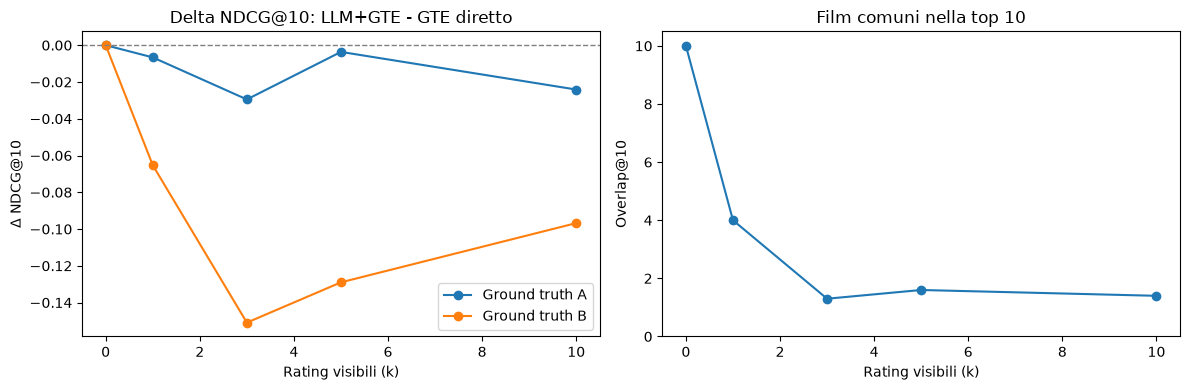

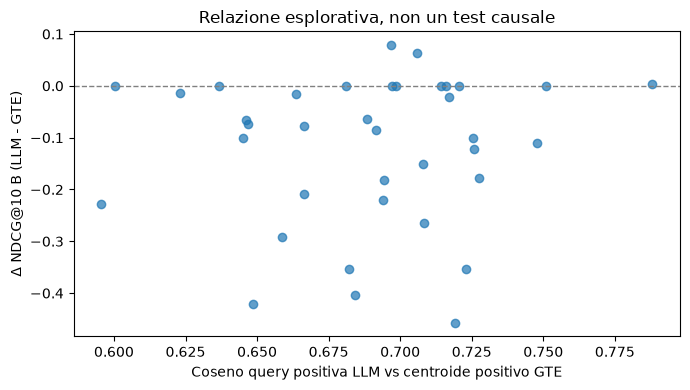

In [11]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for scheme,g in per_case.groupby('scheme'):
    means=g.groupby('k').delta_ndcg10.mean()
    axes[0].plot(means.index,means.values,marker='o',label=f'Ground truth {scheme}')
axes[0].axhline(0,color='gray',linestyle='--',linewidth=1)
axes[0].set(title='Delta NDCG@10: LLM+GTE - GTE diretto',xlabel='Rating visibili (k)',ylabel='Δ NDCG@10')
axes[0].legend()
means=rank_diagnostics.groupby('k')['overlap@10'].mean()
axes[1].plot(means.index,means.values,marker='o')
axes[1].set(title='Film comuni nella top 10',xlabel='Rating visibili (k)',ylabel='Overlap@10',ylim=(0,10.5))
plt.tight_layout();plt.show()

if RUN_VECTOR_DIAGNOSTICS and vector_diag is not None:
    scatter=vector_diag.merge(per_case.loc[per_case.scheme=='B',['scenario_id','k','delta_ndcg10']],on=['scenario_id','k'])
    scatter=scatter.dropna(subset=['cos_querypos_centroid','delta_ndcg10'])
    if not scatter.empty:
        plt.figure(figsize=(7,4))
        plt.scatter(scatter.cos_querypos_centroid,scatter.delta_ndcg10,alpha=.7)
        plt.axhline(0,color='gray',linestyle='--',linewidth=1)
        plt.xlabel('Coseno query positiva LLM vs centroide positivo GTE')
        plt.ylabel('Δ NDCG@10 B (LLM - GTE)')
        plt.title('Relazione esplorativa, non un test causale')
        plt.tight_layout();plt.show()

## 9 — Esportazione privata e lettura scientifica

Le statistiche aggregate del pilota non permettono di inferire che le nuove rappresentazioni miglioreranno i risultati. La diagnostica non deve indurre a modificare prompt/iperparametri sulla base del test.

**Segnali da cercare:** (a) query molto ampie con molti generi, (b) cosine query/centroide molto basso, (c) film in top10 scambiati che restano `unjudged`, (d) penalizzazione negativa che cambia poco il ranking o perde hit, (e) perdita di informazione usando solo titolo/genere anziché testo completo del corpus. Nessuno di questi punti è automaticamente una prova causale.

In [12]:
OUT.mkdir(parents=True,exist_ok=True)
query_diag.to_csv(OUT/'query_text_diagnostics.csv',index=False)
rank_diagnostics.to_csv(OUT/'ranking_overlap_diagnostics.csv',index=False)
per_case.to_csv(OUT/'paired_ranking_changes_A_B.csv',index=False)
annotated.to_csv(OUT/'rankings_annotated_PRIVATE.csv',index=False)
if vector_diag is not None:vector_diag.to_csv(OUT/'query_centroid_cosine.csv',index=False)
if negative_effect is not None and not negative_effect.empty:negative_effect.to_csv(OUT/'negative_query_counterfactual.csv',index=False)
report={'protocol_id':PROTOCOL_ID,'run_mode':RUN_MODE,'n_scenarios':int(len({s for s,k in keys})),
        'n_scenario_levels':int(len(keys)),'model_profile':expected_model,'prompt_hash':expected_prompt,
        'model_query_embeddings_computed':bool(RUN_VECTOR_DIAGNOSTICS),
        'movie_embeddings_recomputed':False,'llm_calls_made':0,
        'qdrant_collection':run_manifest.get('qdrant_collection'),'qdrant_movie_id_key':QDRANT_MOVIE_ID_KEY,
        'file_sources':{'phase_2a':str(RUN.relative_to(ROOT)),'baseline':str(base_path.relative_to(ROOT))},
        'caveats':['validation pilot is exploratory','non-rated films are unjudged',
                   'source indexed movie texts contain possible MovieLens tag leakage',
                   'keyword genre counts are only lexical proxies']}
(OUT/'diagnostic_manifest.json').write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
print('Diagnostica salvata in:',OUT)
print('Maggior parte dei dati: PRIVATE, non importare come feature del recommender.')

Diagnostica salvata in: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_v1/private_evaluation/diagnostics_llm_query/pilot_validation
Maggior parte dei dati: PRIVATE, non importare come feature del recommender.
